In [40]:
import gc
from scipy.io import loadmat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import estimate_motion, interpolate_motion

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG     = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
RADII        = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk)
si.set_global_job_kwargs(**global_job_kwargs)
job_kwargs = dict(n_jobs=-1, progress_bar=True, chunk_duration="1s")

# 
#     This script preprocesses the Fastigial Intan data.
#     Input:
#         .rhs files from Intan
#     Output:
#         Checkpoint after preprocessing
#         Checkpoint after thresholding and calculating MUA peak locations and firing rate
# 

In [41]:
# Load Geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)

In [42]:
nprw_probe.contact_positions

array([[  43,   20],
       [  11,   20],
       [  59,   40],
       [  27,   40],
       [  43,   60],
       [  11,   60],
       [  59,   80],
       [  27,   80],
       [  43,  100],
       [  11,  100],
       [  59,  120],
       [  27,  120],
       [  43,  140],
       [  11,  140],
       [  59,  160],
       [  27,  160],
       [  43,  180],
       [  11,  180],
       [  59,  200],
       [  27,  200],
       [  43,  220],
       [  11,  220],
       [  59,  240],
       [  27,  240],
       [  43,  260],
       [  11,  260],
       [  59,  280],
       [  27,  280],
       [  43,  300],
       [  11,  300],
       [  59,  320],
       [  27,  320],
       [  43,  340],
       [  11,  340],
       [  59,  360],
       [  27,  360],
       [  43,  380],
       [  11,  380],
       [  59,  400],
       [  27,  400],
       [  43,  420],
       [  11,  420],
       [  59,  440],
       [  27,  440],
       [  43,  460],
       [  11,  460],
       [  59,  480],
       [  27,

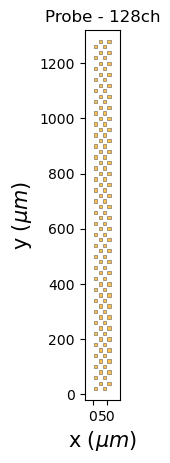

In [ ]:
from probeinterface.plotting import plot_probe
plot_probe(nprw_probe)

plt.show()

In [3]:
# df = nprw_probe.to_dataframe()
# df

In [4]:
# nprw_probe.device_channel_indices

In [5]:
from tqdm import tqdm
import h5py
import gc
from pathlib import Path
import numpy as np

def generate_template(
    chn_data: np.ndarray,  # (NSTIM, interpulse_len)
    template_mode: str,
    repeat_boundaries: np.ndarray,  # 0-based block boundary indices
    window_size: int = 3,
    pca_k: int = 3,
) -> np.ndarray:
    """Generate pulse-by-pulse artifact templates."""
    NSTIM, interpulse_len = chn_data.shape
    template = np.zeros_like(chn_data)
    w = np.linspace(0, 1, interpulse_len)

    # Build is_first_pulse mask
    is_first_pulse = np.zeros(NSTIM, dtype=bool)
    for b in range(len(repeat_boundaries) - 1):
        is_first_pulse[repeat_boundaries[b]] = True

    if template_mode == "local":
        for i in range(NSTIM):
            if is_first_pulse[i]:
                prev_first_idxs = np.where(is_first_pulse[:i])[0]
                if len(prev_first_idxs) >= 1:
                    n_use = min(3, len(prev_first_idxs))
                    ref_idxs = prev_first_idxs[-n_use:]
                    base = chn_data[ref_idxs].mean(axis=0)
                    t = base - base[0]
                    template[i] = t + w * (-t[-1])
                continue
            count = 0
            j = i - 1
            prev_pulses = []
            while j >= 0 and count < window_size:
                if not is_first_pulse[j]:
                    prev_pulses.append(chn_data[j])
                    count += 1
                j -= 1
            if count > 0:
                base = np.stack(prev_pulses).mean(axis=0)
            else:
                base = np.zeros(interpulse_len)
            t = base - base[0]
            template[i] = t + w * (-t[-1])

    elif template_mode == "pca":
        from sklearn.decomposition import PCA
        num_blocks = len(repeat_boundaries) - 1
        for b in range(num_blocks):
            i_start = repeat_boundaries[b]
            i_end   = repeat_boundaries[b + 1]

            # First pulse correction
            prev_first_idxs = np.where(is_first_pulse[:i_start])[0]
            if len(prev_first_idxs) > 0:
                n_use = min(3, len(prev_first_idxs))
                base = chn_data[prev_first_idxs[-n_use:]].mean(axis=0)
            else:
                base = np.zeros(interpulse_len)
            t = base - base[0]
            template[i_start] = t + w * (-t[-1])

            # PCA on rest of block
            if i_end > i_start + 1:
                pca_indices = np.arange(i_start + 1, i_end)
                X = chn_data[pca_indices]
                X_centered = X - X.mean(axis=1, keepdims=True)
                k = min(pca_k, X_centered.shape[0], X_centered.shape[1])
                pca = PCA(n_components=k)
                score = pca.fit_transform(X_centered)
                recon = pca.inverse_transform(score) + X.mean(axis=1, keepdims=True)
                t = recon - recon[:, [0]]
                drift = w[np.newaxis, :] * (-t[:, [-1]])
                template[pca_indices] = t + drift

    return template


def template_subtraction(
    amplifier_data: np.ndarray,
    trigs: np.ndarray,
    params: dict,
    template_mode: str,
    repeat_boundaries: np.ndarray,
    num_repeats: int,
    num_pulse: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Artifact removal via template subtraction + drift correction.

    Returns:
        amplifier_data: corrected trace, shape (n_samples,)
        template: per-pulse template that was subtracted, shape (NSTIM, interpulse_len)
    """
    amplifier_data = amplifier_data.astype(np.float32, copy=True)

    template_leeway   = params["template_leeway"]
    stim_neural_delay = params["stim_neural_delay"]
    window_size       = params["movmean_window"]
    pca_k             = params["pca_k"]
    NSTIM             = trigs.shape[0]

    trigs_beg = trigs[:, 0]
    trigs_end = trigs[:, 1] + stim_neural_delay

    interpulse_len = int(trigs_end[0] - trigs_beg[0] + 1) + 2 * template_leeway
    chn_data = np.full((NSTIM, interpulse_len), np.nan, dtype=np.float32)

    for i in range(NSTIM):
        seg_start = trigs_beg[i] - template_leeway
        seg_end   = trigs_end[i] + template_leeway
        if seg_start < 0 or seg_end >= len(amplifier_data):
            continue
        chn_data[i] = amplifier_data[seg_start:seg_end + 1]

    block_starts = np.array(repeat_boundaries[:-1], dtype=int)
    block_ends   = np.array(repeat_boundaries[1:],  dtype=int)
    boundaries   = np.concatenate([block_starts, [block_ends[-1]]])

    template = generate_template(chn_data, template_mode, boundaries, window_size, pca_k)

    for i in range(NSTIM):
        seg_start = trigs_beg[i] - template_leeway
        seg_end   = trigs_end[i] + template_leeway
        if seg_start < 0 or seg_end >= len(amplifier_data):
            continue
        amplifier_data[seg_start:seg_end + 1] -= template[i]

    # for i in range(NSTIM - 1):
    #     end_i    = trigs_end[i]
    #     beg_next = trigs_beg[i + 1]
    #     mid1 = int(round((end_i + trigs_beg[i]) / 2))
    #     mid2 = int(round((beg_next + trigs_end[i + 1]) / 2))
    #     if mid1 >= mid2 or mid2 >= len(amplifier_data):
    #         continue
    #     seg_idx = np.arange(mid1, mid2 + 1)
    #     template_end_val = amplifier_data[trigs_end[i]]
    #     n = len(seg_idx)
    #     drift = (np.arange(n, dtype=np.float32) / (n - 1) * (-template_end_val)) if n > 1 else np.zeros(1, dtype=np.float32)
    #     amplifier_data[seg_idx] += drift

    return amplifier_data, template


def template_subtraction_all_parallel(
    neural_data: np.ndarray,
    template_params: dict,
    template_mode: str,
    stim_result,
    n_jobs: int = -1,
    out: np.ndarray | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Run template subtraction across all channels, writing results in place to avoid duplicate buffers.

    Returns:
        out: corrected neural data, shape (n_channels, n_samples)
        templates: per-channel, per-pulse templates, shape (n_channels, NSTIM, interpulse_len)
    """
    from joblib import Parallel, delayed

    trigs        = stim_result.trigger_pairs
    block_bounds = stim_result.block_bounds_samples
    n_channels, n_samples = neural_data.shape

    pulse_starts = trigs[:, 0]
    repeat_boundaries = [0]
    for b in range(len(block_bounds)):
        block_end_samp = block_bounds[b, 1]
        in_block = np.where(pulse_starts <= block_end_samp)[0]
        if len(in_block):
            repeat_boundaries.append(int(in_block[-1]) + 1)
    repeat_boundaries = np.array(repeat_boundaries, dtype=int)
    num_repeats = len(repeat_boundaries) - 1
    num_pulse   = trigs.shape[0] / num_repeats

    if out is None:
        out = np.empty_like(neural_data, dtype=np.float32)

    templates = [None] * n_channels

    def process_channel(ch):
        corrected, template = template_subtraction(
            neural_data[ch],
            trigs, template_params, template_mode,
            repeat_boundaries, num_repeats, num_pulse,
        )
        out[ch] = corrected
        templates[ch] = template

    Parallel(n_jobs=n_jobs, prefer="threads")(
        delayed(process_channel)(ch) for ch in tqdm(range(n_channels), desc="artifact correction")
    )
    return out, np.stack(templates).astype(np.float32)

In [37]:
BIN_CKPT = OUT_BASE / "checkpoints" / "NPRW_binary"
BIN_CKPT.mkdir(parents=True, exist_ok=True)

fixed_params = dict(
    NSTIM=0, buffer=25, template_leeway=15,
    stim_neural_delay=13, movmean_window=3,
    med_filt_range=25, gauss_filt_range=25, pca_k=3,
)
STIM_STREAM = NPRW_CFG.get("stim_data_stream")

sess_name = "BL_closed_loop_STIM_003_250528_143802" # BL_closed_loop_STIM_003_250528_143802 and BL_closed_loop_STIM_003_250528_144603 are random stim
sess = INTAN_ROOT / sess_name
bin_path = BIN_CKPT / f"{sess.name}_neural.bin"

In [38]:
# extract stim triggers
import numpy as np
stim_npz_path = NPRW_AUX_DATA / f"{sess.name}_Intan_streams" / "stim_stream.npz"

if stim_npz_path.exists():
    print(f"loading cached stim arrays from {stim_npz_path}")
    loaded = np.load(stim_npz_path, allow_pickle=True)
    stim_arrays = {k: loaded[k] for k in loaded.files if k != "meta"}
else:
    print("no cached stim arrays found, running extraction")
    stim_arrays = rcp.extract_stim_npz(
        sess=sess, out_dir=NPRW_AUX_DATA,
        stim_stream_name=STIM_STREAM,
        chanmap_perm=intan_probe_mapping,
    )
print(stim_arrays.keys())
print(stim_arrays["trigger_pairs"].shape)

no cached stim arrays found, running extraction


[STIM] saved stim stream + triggers -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/aux_data/NPRW/BL_closed_loop_STIM_003_250528_143802_Intan_streams/stim_stream.npz
dict_keys(['stim_traces', 'active_channels', 'trigger_pairs', 'block_bounds_samples', 'pulse_sizes'])
(3000, 2)


In [39]:
DRIFT_CKPT = OUT_BASE / "checkpoints" / "NPRW_drift"
SORT_CKPT  = OUT_BASE / "checkpoints" / "sorting_results" / f'{sess_name}_blanking'
DRIFT_CKPT.mkdir(parents=True, exist_ok=True)
SORT_CKPT.mkdir(parents=True, exist_ok=True)

In [40]:
stim_result = rcp.StimTriggerResult(
    active_channels=stim_arrays["active_channels"],
    trigger_pairs=stim_arrays["trigger_pairs"],
    block_bounds_samples=stim_arrays["block_bounds_samples"],
    pulse_sizes=stim_arrays["pulse_sizes"],
)

import pickle
with open(SORT_CKPT / "stim_result.pkl", "wb") as f:
    pickle.dump(stim_result, f)

In [41]:
# load Intan data
rec_raw = se.read_split_intan_files(sess, mode="concatenate", stream_name=INTAN_STREAM, use_names_as_ids=True)
rec_raw = spre.unsigned_to_signed(rec_raw)
rec_raw = rec_raw.set_probe(nprw_probe)
rec_raw = rcp.reorder_recording_to_geometry(rec_raw, intan_probe_mapping)
print(rec_raw)

ChannelSliceRecording: 128 channels - 30.0kHz - 1 segments - 6,769,408 samples 
                       225.65s (3.76 minutes) - int16 dtype - 1.61 GiB


In [42]:
import spikeinterface as si
import spikeinterface.preprocessing as spre

fs = 30000.0

rec_bp = spre.bandpass_filter(rec_raw, freq_min=float(PARAMS.highpass_hz), freq_max=float(PARAMS.lowpass_hz))
rec_bp = spre.astype(rec_bp, dtype="float32")
rec_cmr = spre.common_reference(rec_bp, reference="local", operator="median", local_radius=(RADII[0], RADII[1]))

print(rec_cmr)

CommonReferenceRecording: 128 channels - 30.0kHz - 1 segments - 6,769,408 samples 
                          225.65s (3.76 minutes) - float32 dtype - 3.23 GiB


In [ ]:
import matplotlib.pyplot as plt
plt.ion()
motion, motion_info = spre.compute_motion(
    rec_cmr, preset="dredge", folder=DRIFT_CKPT, output_motion_info=True, overwrite=True, **job_kwargs
)

import pickle

with open(SORT_CKPT / "motion_info.pkl", "wb") as f:
    pickle.dump(motion_info, f)

%matplotlib inline
from spikeinterface.widgets import plot_motion, plot_motion_info
fig = plt.figure(figsize=(14, 8))
plot_motion_info(
    motion_info, rec_cmr,
    figure=fig,
    depth_lim=(400, 600),
    color_amplitude=True,
    amplitude_cmap="inferno",
    scatter_decimate=10,
)

from spikeinterface.sortingcomponents.motion import interpolate_motion
interpolated_recording = interpolate_motion(
    recording=rec_cmr, motion=motion_info['motion'],
    border_mode="force_extrapolate"
)
interpolated_recording

noise_level (workers: 12 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (workers: 12 processes fork):   0%|          | 0/226 [00:00<?, ?it/s]

In [ ]:
RATES = PARAMS.NPRW_rate_est
ARTRMV_MS_BEFORE = float(RATES.get("remove_ms_before", 20.0))
ARTRMV_TAIL_MS   = float(RATES.get("remove_tail_ms_after", 20.0))

# block_bounds_samples: shape (# stim blocks, 2) in absolute samples
block_bounds = stim_arrays.get("block_bounds_samples")
trigger_pairs = stim_arrays.get("trigger_pairs") # (n_pulses, 2)
stim_channels = stim_arrays['active_channels']

rec_artif_removed = interpolated_recording  # fallback
fs_nprw = rec_raw.get_sampling_frequency()
n_total = rec_raw.get_num_samples()

dur_ms = None

starts_samp = block_bounds[:, 0]
ends_samp   = block_bounds[:, 1]

valid = (ends_samp > starts_samp) & (starts_samp >= 0) & (starts_samp < n_total)
starts_samp = starts_samp[valid]
ends_samp   = ends_samp[valid]

if starts_samp.size:
    dur_ms    = (ends_samp - starts_samp) * 1000.0 / fs_nprw
    ms_after  = float(dur_ms.max() + ARTRMV_TAIL_MS)
    
    rec_artif_removed = si.preprocessing.remove_artifacts(
        interpolated_recording,
        list_triggers=starts_samp.tolist(),
        ms_before=ARTRMV_MS_BEFORE,
        ms_after=ms_after,
        mode="zeros",
    )
else:
    print("[WARN] all block spans invalid or empty; skipping artifact removal.")

# Save preprocessed session
out_dir = NPRW_CKPT_ROOT / f"pp_local_{int(RADII[0])}_{int(RADII[1])}__interp_{sess.name}"
rcp.save_recording(rec_artif_removed, out_dir)
print(f"[{sess.name}] saved artifact_removed -> {out_dir}")

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=120,000 - chunk_memory=58.59 MiB - total_memory=703.12 MiB - chunk_duration=4.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/66 [00:00<?, ?it/s]

[BL_closed_loop_STIM_003_250528_144603] saved artifact_removed -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/NPRW/pp_local_30_150__interp_BL_closed_loop_STIM_003_250528_144603


In [ ]:
# Save the corrected recording to disk so it's serializable for the sorter
saved_rec_path = SORT_CKPT / "rec_corrected_saved"
rec_artif_removed_i16 = spre.astype(rec_artif_removed, dtype="int16")
rec_corrected_saved = rec_artif_removed_i16.save(
    folder=saved_rec_path,
    overwrite=True,
    **job_kwargs,
)
print(rec_corrected_saved)

write_binary_recording 
engine=process - n_jobs=12 - samples_per_chunk=30,000 - chunk_memory=7.32 MiB - total_memory=87.89 MiB - chunk_duration=1.00s


write_binary_recording (workers: 12 processes fork):   0%|          | 0/263 [00:00<?, ?it/s]

BinaryFolderRecording: 128 channels - 30.0kHz - 1 segments - 7,879,424 samples 
                       262.65s (4.38 minutes) - int16 dtype - 1.88 GiB


In [ ]:
# Kilosort4
sorting = ss.run_sorter(
    sorter_name="kilosort4",
    recording=rec_artif_removed,
    folder=SORT_CKPT / "folder_KS4",
    remove_existing_folder=True,
    do_correction=False,
)
sorting = scur.remove_duplicated_spikes(sorting)
sorting = scur.remove_excess_spikes(sorting, rec_artif_removed)
sorting = scur.remove_redundant_units(sorting, align=False, remove_strategy="max_spikes")
sorting.save(folder=SORT_CKPT / "sorting_curated", overwrite=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:12<00:00, 12.44s/it]
/home/bryan/miniconda3/envs/pipeline/lib/python3.10/site-packages/spikeinterface/core/basesorting.py:384: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


NumpyFolder (NumpyFolderSorting): 214 units - 1 segments - 30.0kHz

In [50]:
sorting

UnitsSelectionSorting: 192 units - 1 segments - 30.0kHz

In [51]:
if 'analyzer_precuration' in dir():
    del analyzer_precuration
gc.collect()
import shutil, pathlib
folder = SORT_CKPT / "analyzer_blanking"
if folder.exists():
    shutil.rmtree(folder, ignore_errors=True)
    # force-remove anything left
    import subprocess
    subprocess.run(["rm", "-rf", str(folder)], check=True)

analyzer_precuration = si.create_sorting_analyzer(
    sorting, rec_artif_removed,
    format="binary_folder",
    folder=SORT_CKPT / "analyzer_blanking",
    overwrite=True,
    **job_kwargs,
)
analyzer_precuration.compute(
    [
        "random_spikes", "waveforms", "templates", "noise_levels",
        "spike_amplitudes", "unit_locations", "isi_histograms",
        "correlograms", "principal_components", "quality_metrics",
        "template_similarity",
    ],
    extension_params={
        "principal_components": {"n_components": 3, "mode": "by_channel_global", "whiten": True},
        "quality_metrics": {"metric_names": ["snr", "firing_rate", "rp_violation"],
            "metric_params": {"rp_violation": {"refractory_period_ms": 0.5}},},
    },
    **job_kwargs,
)

estimate_sparsity (workers: 12 processes fork):   0%|          | 0/226 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import spikeinterface.curation as sc

qm = analyzer_precuration.get_extension("quality_metrics").get_data()
passing = qm.query("snr > 3.0 and firing_rate > 0.1 and rp_contamination < 0.2").index.tolist()
print(f"[global QM] {len(passing)}/{len(qm)} units pass SNR/FR/RP filter")
analyzer_precuration = analyzer_precuration.select_units(passing)

analyzer_precuration = analyzer_precuration.save_as(folder=SORT_CKPT / "analyzer_blanking_filtered", format="binary_folder")

[global QM] 95/95 units pass SNR/FR/RP filter


In [ ]:
from spikeinterface.exporters import export_to_phy
export_to_phy(
    analyzer_precuration,
    output_folder=SORT_CKPT / "phy_blanking",
    remove_if_exists=True,
    **job_kwargs,
)
print(f"Phy export -> {SORT_CKPT / 'phy_blanking'}")


write_binary_recording (workers: 12 processes fork):   0%|          | 0/263 [00:00<?, ?it/s]

extract PCs (workers: 12 processes fork):   0%|          | 0/263 [00:00<?, ?it/s]

Run:
phy template-gui  /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_144603_blanking/phy_blanking/params.py
Phy export -> /home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Bert/BL_RW_003_Session_1/results/checkpoints/sorting_results/BL_closed_loop_STIM_003_250528_144603_blanking/phy_blanking


In [ ]:
from spikeinterface.curation import compute_merge_unit_groups
merge_groups = compute_merge_unit_groups(analyzer_precuration, preset="slay", resolve_graph=True)
if merge_groups is not None and len(merge_groups) > 0:
    analyzer_clean = analyzer_precuration.merge_units(merge_unit_groups=merge_groups)
    print(f"[concat] {analyzer_clean.sorting.get_num_units()} units after SLAY merge")
else:
    print(f"[concat] no merges found, {analyzer_precuration.sorting.get_num_units()} units")

[concat] 94 units after SLAY merge


In [ ]:
from scipy.io import savemat
spike_trains = {}
for uid in analyzer_clean.sorting.unit_ids:
    spike_trains[str(uid)] = analyzer_clean.sorting.get_unit_spike_train(uid, segment_index=0)
out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
out_path.mkdir(parents=True, exist_ok=True)
savemat(out_path / "spike_trains.mat",
        {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": float(analyzer_clean.sorting.get_sampling_frequency())})

In [ ]:
analyzer_clean

SortingAnalyzer: 128 channels - 94 units - 1 segments - memory - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, isi_histograms, correlograms, principal_components, quality_metrics, template_similarity, spike_amplitudes

In [ ]:
#merge_units censor_ms to 5 samples, to remove duplicate spikes
merge_unit_groups = [[144, 150], [56, 18]]
remove_unit_ids = [36, 45, 54, 100, 108, 129]

analyzer_clean = analyzer_precuration.merge_units(
    merge_unit_groups=merge_unit_groups,
    censored_period_ms=0.5,
    merging_mode="soft"
)

# remove some units
analyzer_clean = analyzer_clean.remove_units(remove_unit_ids=remove_unit_ids, )

analyzer_clean = analyzer_clean.save_as(folder=SORT_CKPT / "analyzer_blanking_cleaned", format="binary_folder")

In [ ]:
from scipy.io import savemat
spike_trains = {}
for uid in analyzer_clean.sorting.unit_ids:
    spike_trains[str(uid)] = analyzer_clean.sorting.get_unit_spike_train(uid, segment_index=0)
out_path = OUT_BASE / "checkpoints" / "sorting_results" / sess_name / "NPRW"
out_path.mkdir(parents=True, exist_ok=True)
savemat(out_path / "spike_trains.mat",
        {f"unit_{k}": v for k, v in spike_trains.items()} | {"fs": float(analyzer_clean.sorting.get_sampling_frequency())})

In [ ]:
analyzer_clean

SortingAnalyzer: 128 channels - 68 units - 1 segments - memory - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, noise_levels, unit_locations, isi_histograms, correlograms, principal_components, quality_metrics, template_similarity, spike_amplitudes